In [1]:
# ============================================================
# CELL 01 — ENVIRONMENT
# ============================================================

!pip install -U scikit-learn

import os
import random
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import torchvision
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)


print("=" * 60)
print("ENVIRONMENT")
print("=" * 60)

print("Python:", __import__("sys").version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", __import__("sklearn").__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 82.1 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ENVIRONMENT
Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Scikit-learn: 1.9.0
CUDA available: True
GPU: Tesla T4


In [2]:
# ====================================================
# CEL 02 - CONFIGURATION + REPRODUCIBILITY
# ====================================================

# Default seed
SEED = 42

# Seeds for multi-seed experiments
SEEDS = [42, 123, 2024]

# Dataset
DATA_DIR = Path("/content/face_frames")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Image
IMG_SIZE = 224

#Training
BATCH_SIZE = 64
NUM_EPOCHS = 10
LR = 1e-3
WEIGHT_DECAY = 1e-4

# DataLoader
NUM_WORKERS = 4

# Classification
CLASS_NAMES = ["REAL", "FAKE"]
NUM_CLASSES = 1

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def set_seed(seed):
  random.seed(seed)
  np.random.seed(seed)

  torch.manual_seed(seed)

  if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

  # Reproducibility
  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

set_seed(SEED)

print("DATA_DIR:", DATA_DIR)
print("IMG_SIZE:", IMG_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)
print("NUM_EPOCHS:", NUM_EPOCHS)
print("LR:", LR)
print("NUM_WORKERS:", NUM_WORKERS)
print("SEEDS:", SEEDS)
print("DEVICE:", device)

DATA_DIR: /content/face_frames
IMG_SIZE: 224
BATCH_SIZE: 64
NUM_EPOCHS: 10
LR: 0.001
NUM_WORKERS: 4
SEEDS: [42, 123, 2024]
DEVICE: cuda


In [3]:
# ============================================================
# CELL 03 — MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
# Giải nén dataset từ Drive vào ổ đĩa cục bộ Colab (/content/)
!unzip -q /content/drive/MyDrive/face_frames.zip -d /content/

In [5]:
# ============================================================
# CELL 04 — VERIFY DATASET
# ============================================================

for name, path in {
    "TRAIN": TRAIN_DIR,
    "VAL": VAL_DIR,
    "TEST": TEST_DIR,
}.items():

    print(
        f"{name:>5}: "
        f"{'OK' if path.exists() else 'MISSING'}"
        f"  -> {path}"
    )

    if path.exists():
        print("       Classes:", sorted(
            [p.name for p in path.iterdir() if p.is_dir()]
        ))

TRAIN: OK  -> /content/face_frames/train
       Classes: ['FAKE', 'REAL']
  VAL: OK  -> /content/face_frames/val
       Classes: ['FAKE', 'REAL']
 TEST: OK  -> /content/face_frames/test
       Classes: ['FAKE', 'REAL']


In [6]:
# ============================================================
# CELL 05 — DATASET STATISTICS
# ============================================================

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


def get_dataset_statistics(split_dir):
    rows = []

    for class_name in CLASS_NAMES:

        class_dir = split_dir / class_name

        if not class_dir.exists():
            continue

        video_count = 0
        frame_count = 0

        for video_dir in class_dir.iterdir():

            if not video_dir.is_dir():
                continue

            video_count += 1

            for image_path in video_dir.iterdir():

                if image_path.suffix.lower() in IMAGE_EXTENSIONS:
                    frame_count += 1

        rows.append({
            "Class": class_name,
            "Videos": video_count,
            "Frames": frame_count,
        })

    return pd.DataFrame(rows)


for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VAL", VAL_DIR),
    ("TEST", TEST_DIR),
]:

    print(f"\n{'=' * 20} {split_name} {'=' * 20}")

    df = get_dataset_statistics(split_dir)

    display(df)


==================== TRAIN ====================


,Class,Videos,Frames
0,REAL,796,7898
1,FAKE,4781,46448



==================== VAL ====================


,Class,Videos,Frames
0,REAL,102,1020
1,FAKE,610,5982



==================== TEST ====================


,Class,Videos,Frames
0,REAL,102,1009
1,FAKE,609,5878


In [7]:
# ============================================================
# CELL 06 — DEEPFAKE DATASET
# ============================================================

class DeepfakeDataset(Dataset):

    LABEL_MAP = {
        "REAL": 0,
        "FAKE": 1,
    }

    def __init__(self, root_dir, transform=None):

        self.root_dir = Path(root_dir)
        self.transform = transform

        self.samples = []

        for class_name, label in self.LABEL_MAP.items():

            class_dir = self.root_dir / class_name

            if not class_dir.exists():
                continue

            for video_dir in sorted(class_dir.iterdir()):

                if not video_dir.is_dir():
                    continue

                for image_path in sorted(video_dir.iterdir()):

                    if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                        continue

                    self.samples.append({
                        "image_path": image_path,
                        "label": label,
                        "video_id": video_dir.name,
                    })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        sample = self.samples[index]

        with Image.open(sample["image_path"]) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return {
            "image": image,
            "label": torch.tensor(
                sample["label"],
                dtype=torch.float32
            ),
            "video_id": sample["video_id"],
            "image_path": str(sample["image_path"]),
        }

In [8]:
# ============================================================
# CELL 07 — TRANSFORMS
# ============================================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])


eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])

In [9]:
# ============================================================
# CELL 08 — CREATE DATASETS
# ============================================================

train_dataset = DeepfakeDataset(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = DeepfakeDataset(
    VAL_DIR,
    transform=eval_transform
)

test_dataset = DeepfakeDataset(
    TEST_DIR,
    transform=eval_transform
)

print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

Train: 54346
Val:   7002
Test:  6887


In [10]:
# ============================================================
# CELL 09 — CLASS DISTRIBUTION
# ============================================================

train_labels = [
    sample["label"]
    for sample in train_dataset.samples
]

class_counts = np.bincount(train_labels)

for label, count in enumerate(class_counts):

    print(
        f"{CLASS_NAMES[label]:>5}: "
        f"{count:,} "
        f"({count / len(train_labels):.2%})"
    )

 REAL: 7,898 (14.53%)
 FAKE: 46,448 (85.47%)


In [11]:
# ============================================================
# CELL 09B — WEIGHTED RANDOM SAMPLER
# ============================================================

class_weights = 1.0 / class_counts

sample_weights = torch.tensor(
    [class_weights[label] for label in train_labels],
    dtype=torch.double
)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=20000,
    replacement=True,
)

print("WeightedRandomSampler: READY")

WeightedRandomSampler: READY


In [12]:
# ============================================================
# CELL 10 — DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

print("Train batches:", len(train_loader))
print("Val batches:  ", len(val_loader))
print("Test batches: ", len(test_loader))

Train batches: 313
Val batches:   110
Test batches:  108


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [13]:
# ============================================================
# CELL 11 — SANITY CHECK
# ============================================================

batch = next(iter(train_loader))

print("Image shape :", batch["image"].shape)
print("Label shape :", batch["label"].shape)
print("Labels      :", batch["label"][:10])
print("Video IDs   :", batch["video_id"][:5])

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Image shape : torch.Size([64, 3, 224, 224])
Label shape : torch.Size([64])
Labels      : tensor([0., 0., 0., 1., 0., 1., 1., 0., 0., 0.])
Video IDs   : ['original_117', 'original_247', 'original_096', 'DeepFakeDetection_09_18__outside_talking_pan_laughing__3VP8836C', 'original_959']


In [14]:
# ============================================================
# CELL 12 — DATALOADER BENCHMARK
# ============================================================

def benchmark_loader(loader, num_batches=50):

    start = time.time()

    for i, batch in enumerate(loader):

        if i + 1 >= num_batches:
            break

    elapsed = time.time() - start

    print(f"Batches tested : {min(num_batches, len(loader))}")
    print(f"Total time     : {elapsed:.2f} s")
    print(
        f"Average/batch  : "
        f"{elapsed / min(num_batches, len(loader)):.4f} s"
    )


benchmark_loader(train_loader, num_batches=50)

Batches tested : 50
Total time     : 6.64 s
Average/batch  : 0.1328 s


In [15]:
# ============================================================
# CELL 13 — MODEL FACTORY
# ============================================================

def create_model(model_name):

    if model_name == "resnet50":

        model = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        in_features = model.fc.in_features

        model.fc = nn.Linear(
            in_features,
            1
        )

    elif model_name == "efficientnet_b0":

        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        in_features = model.classifier[1].in_features

        model.classifier[1] = nn.Linear(
            in_features,
            1
        )

    elif model_name == "convnext_tiny":

        model = models.convnext_tiny(
            weights=models.ConvNeXt_Tiny_Weights.DEFAULT
        )

        in_features = model.classifier[2].in_features

        model.classifier[2] = nn.Linear(
            in_features,
            1
        )

    else:
        raise ValueError(
            f"Unknown model: {model_name}"
        )

    return model

In [16]:
# ============================================================
# CELL 14 — FREEZE BACKBONE
# ============================================================

def freeze_backbone(model):

    for param in model.parameters():
        param.requires_grad = False

    if hasattr(model, "fc"):

        for param in model.fc.parameters():
            param.requires_grad = True

    elif hasattr(model, "classifier"):

        for param in model.classifier.parameters():
            param.requires_grad = True

    else:
        raise ValueError(
            "Cannot identify classification head."
        )

    return model

In [17]:
# ============================================================
# CELL 15 — PARAMETER CHECK
# ============================================================

def inspect_model(model_name):

    model = create_model(model_name)
    model = freeze_backbone(model)

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    ratio = (
        100.0 * trainable_params / total_params
    )

    print(f"\nModel: {model_name}")
    print(f"Total parameters     : {total_params:,}")
    print(f"Trainable parameters : {trainable_params:,}")
    print(f"Trainable ratio      : {ratio:.4f}%")


for name in [
    "resnet50",
    "efficientnet_b0",
    "convnext_tiny",
]:

    inspect_model(name)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 150MB/s]



Model: resnet50
Total parameters     : 23,510,081
Trainable parameters : 2,049
Trainable ratio      : 0.0087%
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 102MB/s]



Model: efficientnet_b0
Total parameters     : 4,008,829
Trainable parameters : 1,281
Trainable ratio      : 0.0320%
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:02<00:00, 53.5MB/s]



Model: convnext_tiny
Total parameters     : 27,820,897
Trainable parameters : 2,305
Trainable ratio      : 0.0083%


In [18]:
# ============================================================
# CELL 16 — TRAIN ONE EPOCH
# ============================================================

scaler = torch.amp.GradScaler("cuda")

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    num_samples = 0
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        labels = batch["label"].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            logits = model(images).squeeze(1)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        num_samples += batch_size
    return running_loss / num_samples

In [19]:
# ============================================================
# CELL 17 — EVALUATION
# ============================================================

@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion,
):

    model.eval()

    running_loss = 0.0
    num_samples = 0

    all_labels = []
    all_probs = []

    for batch in loader:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        labels = batch["label"].to(
            device,
            non_blocking=True
        )

        logits = model(images).squeeze(1)

        loss = criterion(
            logits,
            labels
        )

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        num_samples += batch_size

        probs = torch.sigmoid(logits)

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probs.extend(
            probs.cpu().numpy()
        )

    labels = np.asarray(all_labels)
    probs = np.asarray(all_probs)

    predictions = (
        probs >= 0.5
    ).astype(int)

    return {
        "loss": running_loss / num_samples,

        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "precision": precision_score(
            labels,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            labels,
            predictions,
            zero_division=0
        ),

        "f1": f1_score(
            labels,
            predictions,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            labels,
            probs
        ),
    }

In [20]:
# ============================================================
# CELL 18 — TRAIN MODEL
# ============================================================

def train_model(
    model_name,
    seed,
    num_epochs=NUM_EPOCHS,
):

    set_seed(seed)

    print("\n" + "=" * 70)
    print(f"TRAINING: {model_name}")
    print("=" * 70)

    model = create_model(model_name)
    model = freeze_backbone(model)
    model = model.to(device)

    criterion = nn.BCEWithLogitsLoss()

    trainable_params = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        trainable_params,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
    )

    best_f1 = -1.0
    best_epoch = 0
    best_state = None

    history = []

    total_start = time.time()

    for epoch in range(num_epochs):

        epoch_start = time.time()

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
        )

        val_metrics = evaluate(
            model,
            val_loader,
            criterion,
        )

        epoch_time = (
            time.time() - epoch_start
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"],
            "val_roc_auc": val_metrics["roc_auc"],
            "epoch_time_sec": epoch_time,
        })

        print(
            f"Epoch [{epoch+1:02d}/{num_epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"F1: {val_metrics['f1']:.4f} | "
            f"AUC: {val_metrics['roc_auc']:.4f} | "
            f"Time: {epoch_time:.1f}s"
        )

        if val_metrics["f1"] > best_f1:

            best_f1 = val_metrics["f1"]
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

    total_time = time.time() - total_start

    model.load_state_dict(best_state)

    history = pd.DataFrame(history)

    print(
        f"\nBest epoch: {best_epoch}"
        f" | Best Val F1: {best_f1:.4f}"
    )

    print(
        f"Total training time: "
        f"{total_time / 60:.2f} min"
    )

    return model, history

In [21]:
# ============================================================
# CELL 19 — PILOT TEST
# ============================================================

#pilot_model, pilot_history = train_model(
#    "resnet50",
#    num_epochs=1,
#)

In [22]:
# ============================================================
# CELL 19 — MULTI-SEED EXPERIMENT CONFIGURATION
# ============================================================

MODEL_NAMES = [
    "resnet50",
    "efficientnet_b0",
    "convnext_tiny",
]

print("Models:")
for model_name in MODEL_NAMES:
    print("-", model_name)

print("\nSeeds:")
for seed in SEEDS:
    print("-", seed)

Models:
- resnet50
- efficientnet_b0
- convnext_tiny

Seeds:
- 42
- 123
- 2024


In [24]:
# ============================================================
# CELL 20 — TEST ONE EXPERIMENT
# ============================================================

test_model, test_history = train_model(
    model_name="resnet50",
    seed=42,
    num_epochs=1,
)


TRAINING: resnet50


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [01/1] | Train Loss: 0.6675 | Val Loss: 0.5499 | F1: 0.8672 | AUC: 0.6381 | Time: 74.9s

Best epoch: 1 | Best Val F1: 0.8672
Total training time: 1.25 min


In [25]:
# ============================================================
# CELL 21 — RUN 3 MODELS × 3 SEEDS
# ============================================================

all_results = []

for seed in SEEDS:

    for model_name in MODEL_NAMES:

        print("\n")
        print("#" * 80)
        print(f"START EXPERIMENT")
        print(f"Model: {model_name}")
        print(f"Seed : {seed}")
        print("#" * 80)

        model, history = train_model(
            model_name=model_name,
            seed=seed,
            num_epochs=NUM_EPOCHS,
        )

        # Find best validation epoch
        best_idx = history["val_f1"].idxmax()
        best_row = history.loc[best_idx]

        result = {
            "model": model_name,
            "seed": seed,
            "best_epoch": int(
                best_row["epoch"]
            ),
            "val_accuracy": float(
                best_row["val_accuracy"]
            ),
            "val_precision": float(
                best_row["val_precision"]
            ),
            "val_recall": float(
                best_row["val_recall"]
            ),
            "val_f1": float(
                best_row["val_f1"]
            ),
            "val_roc_auc": float(
                best_row["val_roc_auc"]
            ),
        }

        all_results.append(result)

        print("\nRESULT:")
        print(result)

print("\n" + "=" * 80)
print("ALL EXPERIMENTS COMPLETED")
print("=" * 80)

print("Number of experiments:", len(all_results))



################################################################################
START EXPERIMENT
Model: resnet50
Seed : 42
################################################################################

TRAINING: resnet50


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [01/10] | Train Loss: 0.6675 | Val Loss: 0.5499 | F1: 0.8672 | AUC: 0.6381 | Time: 69.7s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [02/10] | Train Loss: 0.6526 | Val Loss: 0.6899 | F1: 0.6341 | AUC: 0.6537 | Time: 68.5s


...

Epoch [08/10] | Train Loss: 0.6400 | Val Loss: 0.6536 | F1: 0.6885 | AUC: 0.6928 | Time: 79.6s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [09/10] | Train Loss: 0.6362 | Val Loss: 0.6255 | F1: 0.7258 | AUC: 0.6942 | Time: 80.1s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [10/10] | Train Loss: 0.6361 | Val Loss: 0.7217 | F1: 0.6085 | AUC: 0.6880 | Time: 79.6s

Best epoch: 5 | Best Val F1: 0.7332
Total training time: 13.31 min

RESULT:
{'model': 'convnext_tiny', 'seed': 2024, 'best_epoch': 5, 'val_accuracy': 0.6185375606969438, 'val_precision': 0.9108960039712087, 'val_recall': 0.6135071882313607, 'val_f1': 0.7331934871641195, 'val_roc_auc': 0.6850071456198661}

ALL EXPERIMENTS COMPLETED
Number of experiments: 9


In [26]:
# ============================================================
# CELL 22 — RAW RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(all_results)

display(results_df)

,model,seed,best_epoch,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
0,resnet50,42,1,0.774350,0.871791,0.862755,0.867249,0.638064
1,efficientnet_b0,42,7,0.665524,0.898075,0.686393,0.778094,0.672956
2,convnext_tiny,42,3,0.648529,0.899478,0.662655,0.763115,0.671109
3,resnet50,123,3,0.688232,0.888843,0.725844,0.799117,0.659585
4,efficientnet_b0,123,10,0.665524,0.895997,0.688399,0.778597,0.667826
5,convnext_tiny,123,10,0.736075,0.889706,0.788867,0.836257,0.693666
6,resnet50,2024,6,0.619109,0.901040,0.622534,0.736332,0.667011
7,efficientnet_b0,2024,3,0.640960,0.894091,0.657640,0.757850,0.661885
8,convnext_tiny,2024,5,0.618538,0.910896,0.613507,0.733193,0.685007


In [27]:
# ============================================================
# CELL 23 — SAVE RAW RESULTS
# ============================================================

RAW_RESULTS_PATH = (
    "/content/baseline_results_all_seeds.csv"
)

results_df.to_csv(
    RAW_RESULTS_PATH,
    index=False
)

print(
    "Saved raw results to:",
    RAW_RESULTS_PATH
)

Saved raw results to: /content/baseline_results_all_seeds.csv


In [28]:
# ============================================================
# CELL 24 — MEAN ± STD
# ============================================================

def mean_std(series):
    return (
        f"{series.mean():.4f} ± "
        f"{series.std():.4f}"
    )


summary_table = results_df.groupby(
    "model"
).agg(
    Accuracy=(
        "val_accuracy",
        mean_std
    ),
    Precision=(
        "val_precision",
        mean_std
    ),
    Recall=(
        "val_recall",
        mean_std
    ),
    F1=(
        "val_f1",
        mean_std
    ),
    ROC_AUC=(
        "val_roc_auc",
        mean_std
    ),
)

display(summary_table)

,Accuracy,Precision,Recall,F1,ROC_AUC
model,,,,,
convnext_tiny,0.6677 ± 0.0611,0.9000 ± 0.0106,0.6883 ± 0.0905,0.7775 ± 0.0530,0.6833 ± 0.0114
efficientnet_b0,0.6573 ± 0.0142,0.8961 ± 0.0020,0.6775 ± 0.0172,0.7715 ± 0.0118,0.6676 ± 0.0055
resnet50,0.6939 ± 0.0778,0.8872 ± 0.0147,0.7370 ± 0.1205,0.8009 ± 0.0655,0.6549 ± 0.0150


In [29]:
# ============================================================
# CELL 25 — SAVE SUMMARY
# ============================================================

SUMMARY_PATH = (
    "/content/baseline_comparison_mean_std.csv"
)

summary_table.to_csv(
    SUMMARY_PATH
)

print(
    "Saved summary to:",
    SUMMARY_PATH
)

Saved summary to: /content/baseline_comparison_mean_std.csv


In [ ]:
# ============================================================
# CELL 23 — VALIDATION COMPARISON
# ============================================================

def get_best_metrics(history):

    best_idx = history["val_f1"].idxmax()
    best_row = history.loc[best_idx]

    return {
        "Best Epoch": int(best_row["epoch"]),
        "Accuracy": best_row["val_accuracy"],
        "Precision": best_row["val_precision"],
        "Recall": best_row["val_recall"],
        "F1": best_row["val_f1"],
        "ROC-AUC": best_row["val_roc_auc"],
        "Epoch Time (s)": best_row["epoch_time_sec"],
    }


comparison = pd.DataFrame({
    "ResNet50": get_best_metrics(
        resnet50_history
    ),

    "EfficientNet-B0": get_best_metrics(
        efficientnet_history
    ),

    "ConvNeXt-Tiny": get_best_metrics(
        convnext_history
    ),
}).T

comparison = comparison.sort_values(
    "F1",
    ascending=False,
)

display(comparison)

,Best Epoch,Accuracy,Precision,Recall,F1,ROC-AUC,Epoch Time (s)
ResNet50,1.0,0.774350,0.871791,0.862755,0.867249,0.638064,60.900047
EfficientNet-B0,5.0,0.676093,0.895443,0.702942,0.787601,0.673066,54.382451
ConvNeXt-Tiny,4.0,0.677092,0.898992,0.700769,0.787600,0.686257,72.079600


In [ ]:
# ============================================================
# CELL 24 — SELECT BEST MODEL
# ============================================================

best_model_name = comparison.index[0]

print("=" * 60)
print("BEST BASELINE MODEL")
print("=" * 60)

print("Model:", best_model_name)

display(
    comparison.loc[[best_model_name]]
)

BEST BASELINE MODEL
Model: ResNet50


,Best Epoch,Accuracy,Precision,Recall,F1,ROC-AUC,Epoch Time (s)
ResNet50,1.0,0.77435,0.871791,0.862755,0.867249,0.638064,60.900047


In [ ]:
# ============================================================
# CELL 25 — FINAL TEST
# ============================================================

model_dict = {
    "ResNet50": resnet50_model,
    "EfficientNet-B0": efficientnet_model,
    "ConvNeXt-Tiny": convnext_model,
}

best_model = model_dict[best_model_name]

criterion = nn.BCEWithLogitsLoss()

test_metrics = evaluate(
    best_model,
    test_loader,
    criterion,
)

print("=" * 60)
print("FINAL TEST RESULT")
print("=" * 60)

for metric, value in test_metrics.items():

    print(
        f"{metric:>10}: {value:.4f}"
    )

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


FINAL TEST RESULT
      loss: 0.5483
  accuracy: 0.7773
 precision: 0.8654
    recall: 0.8751
        f1: 0.8702
   roc_auc: 0.6302


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


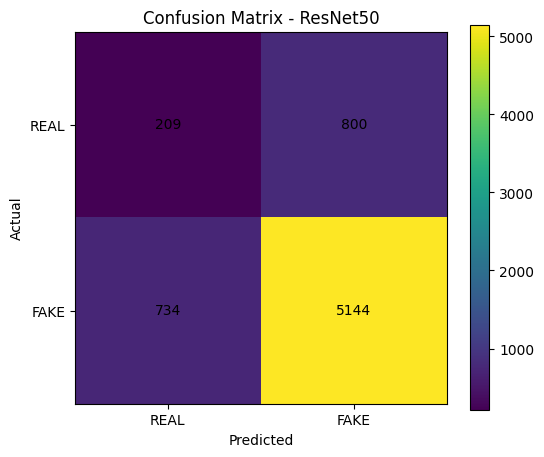

In [ ]:
# ============================================================
# CELL 26 — CONFUSION MATRIX
# ============================================================

@torch.no_grad()
def get_predictions(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    for batch in loader:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        labels = batch["label"].cpu().numpy()

        logits = model(images).squeeze(1)

        probs = torch.sigmoid(logits)

        all_labels.extend(labels)

        all_probs.extend(
            probs.cpu().numpy()
        )

    labels = np.asarray(all_labels)
    probs = np.asarray(all_probs)

    predictions = (
        probs >= 0.5
    ).astype(int)

    return labels, predictions, probs


labels, predictions, probs = get_predictions(
    best_model,
    test_loader,
)

cm = confusion_matrix(
    labels,
    predictions,
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.xticks(
    [0, 1],
    CLASS_NAMES
)

plt.yticks(
    [0, 1],
    CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
        )

plt.colorbar()
plt.show()

In [ ]:
# ============================================================
# CELL 26 — PER-CLASS EVALUATION
# ============================================================

print("=" * 70)
print(f"CLASSIFICATION REPORT — {best_model_name}")
print("=" * 70)

print(
    classification_report(
        labels,
        predictions,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

NameError: name 'best_model_name' is not defined